# 82514 · Sesión S13 — El lazo cerrado: segundo orden, especificaciones y polos

**Bloque 5** · lunes 2 de noviembre de 2026 · 2 h  ·  IQS Universitat Ramon Llull

**Qué hace este cuaderno.** Cierra el lazo de posición del hombro del cuaderno S13a con un proporcional y estudia lo que sale: un segundo orden con ζ y ωn, sus especificaciones medidas con step_info frente a las fórmulas, el límite del proporcional, el plano s y lo que el modelo reducido no ve.

**Se apoya en:** Lynch y Park (2017), caps. 8 y 11; Corke (2023), cap. 9; De Silva et al. (2016), caps. 1 y 4; documentación de python-control.

**Cómo usarlo en clase.** Sigue el guion de la sesión S13 en las diapositivas del bloque 5. Ejecuta la celda de instalación una sola vez al empezar; en Colab tarda unos segundos. Las celdas marcadas **Ejercicio** son para que los trabajen los estudiantes: las soluciones están al final del cuaderno.

---

In [1]:
# Ejecutar una sola vez. En Colab tarda unos segundos.
import importlib, subprocess, sys

def asegurar(mods):
    faltan = []
    for pip_name, import_name in mods:
        try:
            importlib.import_module(import_name)
        except ImportError:
            faltan.append(pip_name)
    if faltan:
        print('Instalando:', ' '.join(faltan))
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + faltan, check=False)
    else:
        print('Todo instalado ya.')

asegurar([('numpy', 'numpy'), ('scipy', 'scipy'), ('matplotlib', 'matplotlib'), ('control==0.10.2', 'control')])

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import control as ct
from scipy.optimize import brentq

np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.figsize'] = (9, 3.4)
plt.rcParams['axes.grid'] = True
IQS_AZUL, IQS_VERDE = '#1B2A80', '#1FA355'
GRIS, AMBAR, NAVY, ROJO = '#8A8FA8', '#B9770E', '#2E3FA3', '#C0392B'
COMA = FuncFormatter(lambda v, p: f'{v:g}'.replace('.', ','))   # ejes con coma decimal

def ejes(*axs):
    for ax in axs:
        ax.xaxis.set_major_formatter(COMA); ax.yaxis.set_major_formatter(COMA)

def coma(x, fmt='.3g'):
    """Un número con coma decimal, para los rótulos de las figuras."""
    return format(x, fmt).replace('.', ',')

print('python-control', ct.__version__, '- listo.')
if ct.__version__ != '0.10.2':
    print('AVISO: este cuaderno se probó con python-control 0.10.2. Ejecuta  !pip install -q control==0.10.2  y reinicia el entorno.')

Instalando: control==0.10.2
python-control 0.10.2 - listo.


> **Aviso para Colab.** La primera celda instala python-control 0.10.2, la versión de todo el bloque 5, en unos segundos. Este cuaderno no depende del S13a: define sus propios datos.
>
> **En clase:** las secciones 1 y 2, con el ejercicio de clase de la sección 2, que se pone en común al acabar el taller. Las secciones 3 y 4 y los ejercicios 1 a 3, en casa: las soluciones están al final.
>
> **No se sube:** este cuaderno no tiene tarea en Moodle.

## 1. Cerrar el lazo con un proporcional

*En clase.*

**Abierto o cerrado.** En lazo abierto se manda una tensión y se mira qué pasa: con el integrador de la planta, una tensión constante hace girar el hombro sin parar. En lazo cerrado, el encoder mide q, se compara con la referencia q_ref y la tensión depende del error, e = q_ref − q.

**La planta y el controlador.** La planta es el hombro estirado del cuaderno S13a, P(s) = Q(s)/V(s) = 0,4/(s·(0,216·s + 1)), sin gravedad. El controlador más simple es un proporcional, V = K_p·e, con K_p en V/rad. Cerrando el lazo, Q = P·K_p·(Q_ref − Q), y despejando:

`Q(s)/Q_ref(s) = K_p·P(s)/(1 + K_p·P(s))` = 1,852·K_p/(s² + 4,630·s + 1,852·K_p)

El denominador es el **polinomio característico** del lazo, y sus raíces, los **polos del lazo**: los fija K_p. Comparando con la forma estándar de un segundo orden, `ω_n²/(s² + 2·ζ·ω_n·s + ω_n²)`:

- ω_n = √(1,852·K_p) es la **frecuencia natural**;
- 2·ζ·ω_n = 1/τ_m = 4,630, así que ζ·ω_n = 2,315 queda **fijo**, y ζ, el **amortiguamiento**, vale 1/(2·τ_m·ω_n).

**Un masa-muelle-amortiguador.** K_p hace de muelle; la contratensión, de amortiguador; J', de masa. Es la ecuación del acelerómetro de S6, donde la frecuencia natural se llamaba ω₀ (no es la ω₀ de vacío del motor de S7). Amortigua porque mandamos en tensión: con el amplificador de corriente de S7 no habría amortiguador y el proporcional solo oscilaría; lo arregla el término derivativo, en S14.

En python-control, `ct.feedback(Kp*P, 1)` cierra el lazo: resta la salida medida de la referencia, con realimentación unitaria. En el código, el lazo cerrado se llama `lazo`.

In [2]:
TM, K0 = 0.216, 0.4                  # el hombro estirado (cuaderno S13a): tau_m [s] y 1/(G·K) [rad/s por voltio]
P = ct.tf([K0], [TM, 1, 0], inputs='V', outputs='q', name='P')    # Q(s)/V(s), la planta

def lazo(Kp, tm=TM):
    """El lazo cerrado con un proporcional Kp [V/rad]; tm es la tau_m de la postura."""
    return ct.feedback(Kp*ct.tf([K0], [tm, 1, 0]), 1)

num, den = lazo(1.0).num[0][0], lazo(1.0).den[0][0]
print(f'Con Kp = 1 V/rad: Q/Q_ref = {num[-1]/den[0]:.3f}/(s² + {den[1]/den[0]:.3f} s + {den[2]/den[0]:.3f})')
print(f'zeta·wn = 1/(2·TM) = {1/(2*TM):.4f} 1/s, para cualquier Kp')

Con Kp = 1 V/rad: Q/Q_ref = 1.852/(s² + 4.630 s + 1.852)
zeta·wn = 1/(2·TM) = 2.3148 1/s, para cualquier Kp


Ahora los polos al subir K_p. El polo doble, ζ = 1, sale cuando se anula el discriminante del polinomio característico, 4,630² − 4·1,852·K_p = 0, es decir, con K_p = 4,630²/(4·1,852); sin redondear, 1/(4·0,4·0,216) = 2,8935 V/rad: en el código, `Kp_c = 1/(4*K0*TM)`. Ojo con el redondeo: con 2,894 en lugar de 2,8935, los polos ya son complejos, −2,315 ± 0,03j.

In [3]:
Kp_c = 1/(4*K0*TM)                   # el Kp del polo doble: zeta = 1
print(f'Kp_c = 1/(4·K0·TM) = {Kp_c:.6f} V/rad   polos {np.round(ct.poles(lazo(Kp_c)), 5)}')
print(f'con el redondeo 2.894:             polos {np.round(ct.poles(lazo(2.894)), 3)}')
print()
print(f"{'Kp [V/rad]':>10} {'polos del lazo':>32} {'wn [rad/s]':>11} {'zeta':>6}")
for Kp in (0.5, 1.0, Kp_c, 6.08, 11.6, 72.3):
    wn = np.sqrt(K0/TM*Kp)            # wn**2 = 1.852*Kp
    z = 1/(2*TM*wn)                    # 2·zeta·wn = 1/TM
    print(f'{Kp:10.4f} {str(np.round(ct.poles(lazo(Kp)), 3)):>32} {wn:11.3f} {z:6.3f}')

Kp_c = 1/(4·K0·TM) = 2.893519 V/rad   polos [-2.3148+0.j -2.3148+0.j]
con el redondeo 2.894:             polos [-2.315+0.03j -2.315-0.03j]

Kp [V/rad]                   polos del lazo  wn [rad/s]   zeta
    0.5000          [-4.42 +0.j -0.209+0.j]       0.962  2.406
    1.0000          [-4.187+0.j -0.442+0.j]       1.361  1.701
    2.8935          [-2.315+0.j -2.315+0.j]       2.315  1.000
    6.0800    [-2.315+2.429j -2.315-2.429j]       3.355  0.690
   11.6000    [-2.315+4.015j -2.315-4.015j]       4.635  0.499
   72.3000  [-2.315+11.337j -2.315-11.337j]      11.571  0.200


Los polos salen de 0 y de −4,63 (con K_p = 0,5, dos polos reales), se juntan en −2,315 con K_p = 2,89 V/rad y desde ahí suben en vertical: la parte real se queda en −1/(2·τ_m) = −2,315 para cualquier K_p mayor. Como ζ·ω_n está fijo, `K_p = ω_n²/1,852 = (2,315/ζ)²/1,852 = 1/(4·0,4·0,216·ζ²) = 2,8935/ζ²`.

**Tres regímenes.** Con ζ > 1, **sobreamortiguado**: dos polos reales, dos exponenciales, despacio y sin pasarse. Con ζ = 1, **crítico**: lo más rápido sin pasarse. Con ζ < 1, **subamortiguado**: polos complejos, −ζ·ω_n ± j·ω_d, y la respuesta oscila a ω_d = ω_n·√(1 − ζ²), la **frecuencia amortiguada**. Subir K_p sube ω_n y baja ζ: sube antes, pero oscila más. Es la figura de la diapositiva 13.

zeta = 1.50   Kp =   1.29 V/rad   polos [-4.04+0.j -0.59+0.j]
zeta = 1.00   Kp =   2.89 V/rad   polos [-2.31+0.j -2.31+0.j]
zeta = 0.69   Kp =   6.08 V/rad   polos [-2.31+2.43j -2.31-2.43j]
zeta = 0.50   Kp =  11.57 V/rad   polos [-2.31+4.01j -2.31-4.01j]
zeta = 0.20   Kp =  72.34 V/rad   polos [-2.31+11.34j -2.31-11.34j]


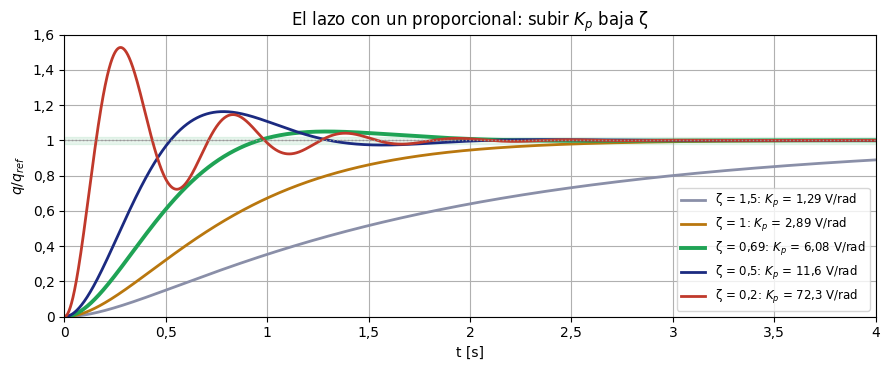

In [4]:
t = np.linspace(0, 4, 4001)
fig, ax = plt.subplots(figsize=(9, 3.8))
for z, col in ((1.5, GRIS), (1.0, AMBAR), (0.69, IQS_VERDE), (0.5, IQS_AZUL), (0.2, ROJO)):
    Kp = Kp_c/z**2                     # Kp = 2.8935/zeta**2
    _, y = ct.step_response(lazo(Kp), t)
    ax.plot(t, y, color=col, lw=2.8 if z == 0.69 else 2,
            label=f'ζ = {coma(z, "g")}: ' + r'$K_p$' + f' = {coma(Kp)} V/rad')
    print(f'zeta = {z:4.2f}   Kp = {Kp:6.2f} V/rad   polos {np.round(ct.poles(lazo(Kp)), 2)}')
ax.axhspan(0.98, 1.02, color=IQS_VERDE, alpha=0.10); ax.axhline(1, color='#999', lw=1, ls=':')
ax.set_xlabel('t [s]'); ax.set_ylabel(r'$q/q_{ref}$'); ax.set_xlim(0, 4); ax.set_ylim(0, 1.6)
ax.set_title('El lazo con un proporcional: subir ' + r'$K_p$' + ' baja ζ'); ax.legend(loc='lower right', fontsize=8.5)
ejes(ax); plt.tight_layout(); plt.show()

## 2. Especificaciones

*En clase.*

Cinco números juzgan una respuesta al escalón. **Rapidez:** t_r, el tiempo de subida, del 10 al 90 % del valor final; t_p, el del pico, el primer máximo. **Precisión:** M_p, la sobreoscilación, cuánto se pasa, en %; t_s, el tiempo de establecimiento, cuando entra en la banda del 2 % y ya no sale; e_ss, el error en régimen, el que queda (sin gravedad, cero, por el integrador de la planta).

**De dónde salen**, con ζ < 1. Los picos y los valles de la oscilación caen sobre 1 ± e^(−ζ·ω_n·t), la **envolvente de los picos**; entre pico y pico la respuesta puede salirse un poco (su desviación del valor final llega hasta e^(−ζ·ω_n·t)/√(1−ζ²)). En el pico, t_p = π/ω_d, la respuesta toca la envolvente, así que lo que se pasa es justo la envolvente en ese instante: `M_p = e^(−ζ·ω_n·t_p) = e^(−π·ζ/√(1−ζ²))`, exacta y función solo de ζ. Para t_s, la envolvente baja al 2 % cuando ζ·ω_n·t_s = ln 50 = 3,91: **t_s ≈ 4/(ζ·ω_n)**, una regla sobre la envolvente (con la banda del 1 %, 4,6/(ζ·ω_n): decid siempre la banda). La subida, t_r ≈ 1,8/ω_n, es la regla más floja.

`ct.step_info(lazo(Kp), T=t)` las mide sobre la respuesta simulada, con la malla de tiempos `t`: `RiseTime`, `PeakTime`, `Overshoot` y `SettlingTime` (banda del 2 %), y `SteadyStateValue`, el valor final, de donde sale e_ss. M_p depende solo de ζ, y cuatro valores merecen memoria:

In [5]:
def mp(z):
    """Sobreoscilación exacta, en %, de un segundo orden con zeta < 1."""
    return 100*np.exp(-np.pi*z/np.sqrt(1 - z**2)) if z < 1 else 0.0

for z in (0.1, 0.5, 0.7, 0.8):
    print(f'zeta = {z}:  Mp = {mp(z):5.1f} %')

zeta = 0.1:  Mp =  72.9 %
zeta = 0.5:  Mp =  16.3 %
zeta = 0.7:  Mp =   4.6 %
zeta = 0.8:  Mp =   1.5 %


Las fórmulas frente a `step_info`, con ζ = 0,5 (K_p = 11,6 V/rad): la curva de la diapositiva 15.

In [6]:
t = np.linspace(0, 6, 60001)               # malla fina: step_info mide sobre ella
z = 0.5
Kp = Kp_c/z**2
wn = np.sqrt(K0/TM*Kp); wd = wn*np.sqrt(1 - z**2)
si = ct.step_info(lazo(Kp), T=t)
print(f'zeta = {z}, Kp = {Kp:.2f} V/rad, wn = {wn:.3f} rad/s, wd = {wd:.3f} rad/s')
print(f"{'':12s} {'fórmula':>9} {'step_info':>10}")
print(f"{'Mp [%]':12s} {mp(z):9.1f} {si['Overshoot']:10.1f}    exacta")
print(f"{'tp [s]':12s} {np.pi/wd:9.3f} {si['PeakTime']:10.3f}    exacta: pi/wd")
print(f"{'ts [s]':12s} {4/(z*wn):9.3f} {si['SettlingTime']:10.3f}    regla 4/(zeta·wn); con ln 50: {np.log(50)/(z*wn):.3f}")
print(f"{'tr [s]':12s} {1.8/wn:9.3f} {si['RiseTime']:10.3f}    regla 1.8/wn, la más floja")

zeta = 0.5, Kp = 11.57 V/rad, wn = 4.630 rad/s, wd = 4.009 rad/s
               fórmula  step_info
Mp [%]            16.3       16.3    exacta
tp [s]           0.784      0.784    exacta: pi/wd
ts [s]           1.728      1.745    regla 4/(zeta·wn); con ln 50: 1.690
tr [s]           0.389      0.354    regla 1.8/wn, la más floja


**El ejemplo del 5 %** (diapositiva 17). El hombro estirado, con un proporcional. Queremos un 5 % de sobreoscilación. ¿Qué K_p? ¿Cuándo llega al pico y cuándo se asienta? ¿Cumple un t_s < 1,5 s? Tres pasos: ζ, despejado de la fórmula de M_p; ω_n, de la parte real fija, ζ·ω_n = 2,315; y K_p, de ω_n² = 1,852·K_p.

In [7]:
Mp_obj = 5.0
z5 = -np.log(Mp_obj/100)/np.sqrt(np.pi**2 + np.log(Mp_obj/100)**2)   # paso 1: zeta, de Mp
wn5 = 1/(2*TM*z5)                                                    # paso 2: zeta·wn = 1/(2·TM)
Kp5 = wn5**2*TM/K0                                                   # paso 3: wn² = (K0/TM)·Kp
wd5 = wn5*np.sqrt(1 - z5**2)
print(f'zeta = {z5:.3f}   wn = {wn5:.3f} rad/s   Kp = {Kp5:.2f} V/rad   wd = {wd5:.2f} rad/s')
print(f'polos {np.round(ct.poles(lazo(Kp5)), 2)}')
print(f'predicción: tp = pi/wd = {np.pi/wd5:.3f} s   ts ≈ 4/(zeta·wn) = {4/(z5*wn5):.2f} s')
si5 = ct.step_info(lazo(Kp5), T=t)
print(f"medido:     Mp = {si5['Overshoot']:.1f} %   tp = {si5['PeakTime']:.3f} s   ts = {si5['SettlingTime']:.2f} s   tr = {si5['RiseTime']:.3f} s")
print('¿Cumple ts < 1.5 s?', si5['SettlingTime'] < 1.5)

zeta = 0.690   wn = 3.354 rad/s   Kp = 6.08 V/rad   wd = 2.43 rad/s
polos [-2.31+2.43j -2.31-2.43j]
predicción: tp = pi/wd = 1.294 s   ts ≈ 4/(zeta·wn) = 1.73 s
medido:     Mp = 5.0 %   tp = 1.294 s   ts = 1.79 s   tr = 0.625 s
¿Cumple ts < 1.5 s? False


El t_s < 1,5 s no se cumple con el 5 %. ¿Hay alguna K_p que cumpla a la vez M_p < 5 % y t_s < 1,5 s con el brazo estirado? Un barrido de K_p de 3 a 7 V/rad lo dice:

In [8]:
t = np.linspace(0, 6, 6001)
print(f"{'Kp [V/rad]':>10} {'zeta':>6} {'Mp [%]':>7} {'ts [s]':>7}")
for Kp in np.arange(3.0, 7.01, 0.25):
    si = ct.step_info(lazo(Kp), T=t)
    z = 1/(2*TM*np.sqrt(K0*Kp/TM))
    marca = '  <- cumple' if si['Overshoot'] < 5 and si['SettlingTime'] < 1.5 else ''
    print(f"{Kp:10.2f} {z:6.3f} {si['Overshoot']:7.2f} {si['SettlingTime']:7.3f}{marca}")

Kp [V/rad]   zeta  Mp [%]  ts [s]
      3.00  0.982    0.00   2.389
      3.25  0.944    0.01   2.115
      3.50  0.909    0.10   1.886
      3.75  0.878    0.31   1.697
      4.00  0.851    0.62   1.542
      4.25  0.825    1.02   1.413  <- cumple
      4.50  0.802    1.48   1.307  <- cumple
      4.75  0.780    1.98   1.217  <- cumple
      5.00  0.761    2.52   1.850
      5.25  0.742    3.08   1.862
      5.50  0.725    3.65   1.849
      5.75  0.709    4.23   1.826
      6.00  0.694    4.82   1.797
      6.25  0.680    5.41   1.766
      6.50  0.667    6.00   1.733
      6.75  0.655    6.58   1.700
      7.00  0.643    7.16   1.668


Solo cumplen 4,25, 4,5 y 4,75 V/rad; con un barrido más fino, la ventana va de 4,08 a 4,76 V/rad (ζ de 0,84 a 0,78), y con ζ = 0,8 (K_p = 4,52) sale un 1,5 % y t_s = 1,30 s, la curva verde de la diapositiva 17. t_s salta cuando la sobreoscilación entra en la banda del 2 %: la respuesta entra subiendo y ya no sale, y t_s lo marca la subida, no la envolvente. Por eso la regla 4/(ζ·ω_n) falla ahí. Con solo K_p, t_s no baja de 1,21 s, justo antes del borde (K_p = 4,759, M_p = 2 %): para bajar de 1 s hace falta mover la parte real, y eso es el término D de S14.

### Ejercicio de clase (en clase; se pone en común al acabar el taller)

La misma K_p del ejemplo, 6,08 V/rad, con el brazo **plegado**: τ_m = 0,1264 s (cuaderno S13a, sección 3). ¿Qué ζ, qué M_p y qué t_s salen? Después, al revés: ¿qué K_p da el 5 % con el brazo plegado, y qué pasa con esa K_p cuando el brazo se estira? En cualquier postura, ω_n = √(0,4·K_p/τ_m) y ζ = 1/(2·τ_m·ω_n).

In [9]:
# Ejercicio de clase: la misma Kp con el brazo plegado
TM_PLEG = 0.1264                       # tau_m con el brazo plegado [s]
t = np.linspace(0, 6, 60001)
# wn = np.sqrt(K0*Kp5/TM_PLEG)
# zeta = 1/(2*TM_PLEG*wn)
# print(zeta, ct.step_info(lazo(Kp5, TM_PLEG), T=t))
# Kp_pleg = ...                        # el 5 % con el brazo plegado: zeta = z5
# print(ct.step_info(lazo(Kp_pleg), T=t))   # y esa Kp, con el brazo estirado

### Ejercicio 1 (en casa)

Para H(s) = 25/(s² + 4·s + 25), calcula a mano ω_n, ζ, la sobreoscilación y el tiempo de establecimiento por la regla 4/(ζ·ω_n). Después mídelos con `ct.step_info` y explica las diferencias.

In [15]:
# Ejercicio 1
H = ct.tf([25], [1, 4, 25])
wn1 = np.sqrt(25)
z1 = 4/(2*wn1)
tp1 = np.pi/(wn1*np.sqrt(1 - z1**2))
si1 = ct.step_info(H, T=np.linspace(0, 6, 60001))
print(f"A mano: wn = {wn1:.1f} rad/s   zeta = {z1:.1f}   Mp = {mp(z1):.1f} %   "
      f"ts = {4/(z1*wn1):.2f} s   tr = {1.8/wn1:.2f} s   tp = {tp1:.3f} s")
print(f"Medido: Mp = {si1['Overshoot']:.1f} %   ts = {si1['SettlingTime']:.2f} s   "
      f"tr = {si1['RiseTime']:.2f} s   tp = {si1['PeakTime']:.3f} s")

A mano: wn = 5.0 rad/s   zeta = 0.4   Mp = 25.4 %   ts = 2.00 s   tr = 0.36 s   tp = 0.686 s
Medido: Mp = 25.4 %   ts = 1.68 s   tr = 0.29 s   tp = 0.686 s


## 3. El plano s

*En casa.*

**El criterio.** El lazo es estable si y solo si todas las raíces del polinomio característico tienen parte real negativa: todos los polos a la izquierda del eje imaginario. Un polo con parte real positiva es una exponencial que crece; uno sobre el eje, como el integrador solo, en s = 0, está en la frontera: ni se apaga ni crece.

**Cómo se lee.** Un par de polos complejos es −σ ± j·ω_d, con σ = ζ·ω_n. Más a la izquierda, más rápido, porque la envolvente es e^(−σ·t); más arriba, más oscilación. Y el ángulo φ que forma el polo con el eje real negativo cumple cos φ = ζ: la recta de ζ = 0,69 va a 46°.

**El lugar de las raíces** es el camino que siguen los polos del lazo al subir K_p. El del nuestro está en la figura, con los ejes a la misma escala para que el ángulo se vea tal cual: los polos salen de 0 y de −4,63, se juntan en −2,315 y suben en vertical. Nunca cruzan al semiplano derecho, pero su parte real no pasa de −2,315.

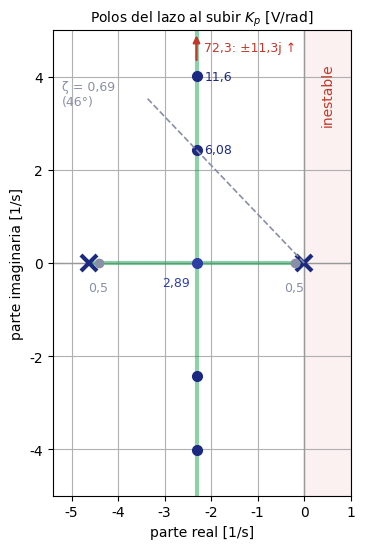

Kp =    0.50 V/rad   estable: True
Kp =    6.08 V/rad   estable: True
Kp =   72.30 V/rad   estable: True
Kp = 1000.00 V/rad   estable: True
La planta sola, polos [-4.63+0.j  0.  +0.j] -> estable: False (el integrador, en la frontera)
Con Kp = 6.08: ángulo con el eje real 46.4°, arccos(zeta) = 46.4°


In [11]:
kps = np.concatenate([np.linspace(0.01, Kp_c, 300), np.linspace(Kp_c, 80, 600)])
polos = np.array([ct.poles(lazo(k)) for k in kps])        # el lugar de las raíces, calculado
fig, ax = plt.subplots(figsize=(4.6, 5.6))
ax.axvspan(0, 1.0, color=ROJO, alpha=0.07); ax.text(0.5, 4.3, 'inestable', color=ROJO, rotation=90, ha='center', va='top')
ax.axhline(0, color='#999', lw=1); ax.axvline(0, color='#999', lw=1)
ax.plot(polos[:, 0].real, polos[:, 0].imag, color=IQS_VERDE, lw=3, alpha=0.5)
ax.plot(polos[:, 1].real, polos[:, 1].imag, color=IQS_VERDE, lw=3, alpha=0.5)
ax.plot([-1/TM, 0], [0, 0], 'x', color=IQS_AZUL, ms=12, mew=3)
p = ct.poles(lazo(0.5)).real                              # dos polos reales
ax.plot(p, [0, 0], 'o', color=GRIS, ms=6)
for x in p:
    ax.text(x, -0.38, '0,5', color=GRIS, fontsize=9, ha='center', va='top')
ax.plot([-1/(2*TM)], [0], 'o', color=NAVY, ms=7); ax.text(-2.45, -0.5, coma(Kp_c), color=NAVY, fontsize=9, ha='right')
for k in (6.08, 11.6):                                     # complejos: suben en vertical
    p = ct.poles(lazo(k))
    ax.plot(p.real, p.imag, 'o', color=IQS_AZUL, ms=7)
    ax.text(-2.15, abs(p.imag[0]), coma(k), color=IQS_AZUL, fontsize=9, va='center')
ax.annotate('', xy=(-1/(2*TM), 4.95), xytext=(-1/(2*TM), 4.3), arrowprops=dict(arrowstyle='-|>', color=ROJO, lw=1.6))
ax.text(-2.15, 4.62, '72,3: ±11,3j ↑', color=ROJO, fontsize=9, va='center')
r = np.linspace(0, 4.9, 10); phi = np.arccos(z5)
ax.plot(-r*np.cos(phi), r*np.sin(phi), color=GRIS, lw=1.2, ls='--')
ax.text(-5.2, 3.4, f'ζ = {coma(z5, ".2f")}\n({np.degrees(phi):.0f}°)', color=GRIS, fontsize=9)
ax.set_aspect('equal'); ax.set_xlim(-5.4, 1.0); ax.set_ylim(-5, 5)
ax.set_xlabel('parte real [1/s]'); ax.set_ylabel('parte imaginaria [1/s]')
ax.set_title('Polos del lazo al subir ' + r'$K_p$' + ' [V/rad]', fontsize=10); ejes(ax)
plt.tight_layout(); plt.show()

for k in (0.5, 6.08, 72.3, 1000.0):
    print(f'Kp = {k:7.2f} V/rad   estable: {np.all(ct.poles(lazo(k)).real < 0)}')
print('La planta sola, polos', np.round(ct.poles(P), 2), '-> estable:', np.all(ct.poles(P).real < 0),
      '(el integrador, en la frontera)')
p5 = ct.poles(lazo(Kp5))[0]
print(f'Con Kp = {Kp5:.2f}: ángulo con el eje real {np.degrees(np.arctan2(abs(p5.imag), -p5.real)):.1f}°, '
      f'arccos(zeta) = {np.degrees(np.arccos(z5)):.1f}°')

## 4. Lo que el modelo reducido no ve

*En casa.*

El lazo reducido nunca se hace inestable: sus polos suben pero no cruzan. Es un artefacto de haber despreciado L. Con L, la planta tiene tres polos, `Q(s)/V(s) = (K/G)/(s·(L·J'·s² + R·J'·s + K²))`, y el polinomio característico del lazo es de tercer grado:

`L·J'·s³ + R·J'·s² + K²·s + (K/G)·K_p = 0`

En el borde de la estabilidad hay un polo sobre el eje imaginario, s = j·ω_u, con ω_u la frecuencia de la oscilación. Sustituyendo y separando la parte real y la imaginaria: ω_u² = K²/(L·J'), así que ω_u ≈ 96 rad/s, y la **ganancia última**, `K_u = R·J'·ω_u²·G/K = R·K·G/L` = 5000 V/rad. Por encima, el lazo oscila cada vez más.

En python-control, `ct.margin(Pq3)` devuelve cuatro números: el **margen de ganancia** `gm`, el factor por el que se puede multiplicar la ganancia del lazo antes de llegar al borde de la estabilidad, y la frecuencia `wg` donde se mide; y el margen de fase y su frecuencia, otra medida de la distancia al borde que en S13 no hace falta. Aplicado a la planta sola (K_p = 1), `gm` es directamente la ganancia última.

polos de la planta con L: [-1995.36    -4.64     0.  ]
ct.margin: gm = 5000.0 a wg = 96.2 rad/s
a mano:    Ku = R·K·G/L = 5000 V/rad   wu = sqrt(K²/(L·J')) = 96.2 rad/s
Ku es 823 veces la Kp del ejemplo del 5 %
Kp =    6.08: polos [-1995.37+0.j      -2.32+2.43j    -2.32-2.43j]   estable: True
Kp = 4000.00: polos [-1999.08 +0.j      -0.46+86.08j    -0.46-86.08j]   estable: True
Kp = 5500.00: polos [-2000.46  +0.j       0.23+100.91j     0.23-100.91j]   estable: False


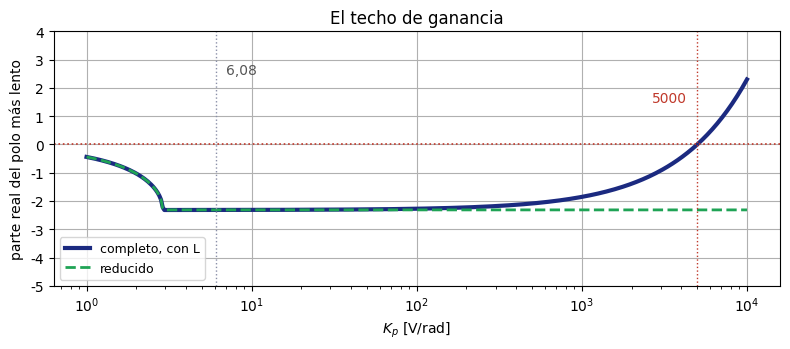

In [12]:
V_BUS, R, L, K, JM, G = 24.0, 2.0, 1e-3, 0.05, 1e-4, 50     # el motor de S7 y la reductora de 50
Jp = JM + 0.425/G**2                                           # J' con el brazo estirado
Pq3 = ct.tf([K/G], [L*Jp, R*Jp, K**2, 0], inputs='V', outputs='q', name='Pq3')   # con L: tres polos
print('polos de la planta con L:', np.round(ct.poles(Pq3).real, 2))

gm, pm, wg, wp = ct.margin(Pq3)
print(f'ct.margin: gm = {gm:.1f} a wg = {wg:.1f} rad/s')
print(f'a mano:    Ku = R·K·G/L = {R*K*G/L:.0f} V/rad   wu = sqrt(K²/(L·J\')) = {np.sqrt(K**2/(L*Jp)):.1f} rad/s')
print(f'Ku es {gm/Kp5:.0f} veces la Kp del ejemplo del 5 %')
for k in (Kp5, 4000.0, 5500.0):
    p = ct.poles(ct.feedback(k*Pq3, 1))
    print(f'Kp = {k:7.2f}: polos {np.round(p, 2)}   estable: {np.all(p.real < 0)}')

kps = np.logspace(0, 4, 400)
red = [ct.poles(lazo(k)).real.max() for k in kps]
com = [ct.poles(ct.feedback(k*Pq3, 1)).real.max() for k in kps]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.semilogx(kps, com, color=IQS_AZUL, lw=3, label='completo, con L')
ax.semilogx(kps, red, color=IQS_VERDE, lw=2, ls='--', label='reducido')
ax.axhline(0, color=ROJO, lw=1.2, ls=':'); ax.axvline(5000, color=ROJO, lw=1, ls=':')
ax.axvline(Kp5, color=GRIS, lw=1, ls=':'); ax.text(7, 2.5, '6,08', color='#555')
ax.text(4300, 1.5, '5000', color=ROJO, ha='right')
ax.set_xlabel(r'$K_p$ [V/rad]'); ax.set_ylabel('parte real del polo más lento'); ax.set_ylim(-5, 4)
ax.set_title('El techo de ganancia'); ax.legend(loc='lower left', fontsize=9)
ax.yaxis.set_major_formatter(COMA); plt.tight_layout(); plt.show()

**El techo de tensión.** El motor no da más de 24 V, ni menos de −24 V. Al arrancar un giro Δq el error es Δq, y la tensión, K_p·Δq. Para el giro de 29° de S12 (0,506 rad): con 6,08 V/rad, 3,1 V; con 72,3 V/rad (ζ = 0,2), 36,6 V, que el motor no puede dar: se satura. La saturación y sus consecuencias, en S14.

Kp =  6.08 V/rad: V(0) =  3.08 V, mínimo  -0.15 V
Kp = 72.30 V/rad: V(0) = 36.59 V, mínimo -19.27 V


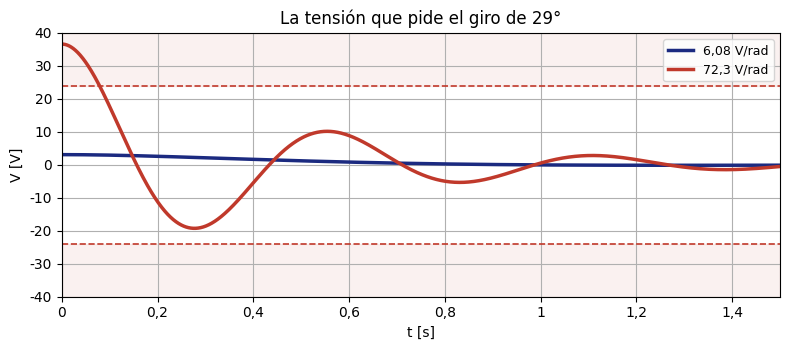

Con 6.08 V/rad, satura un escalón de más de 3.95 rad (226°)


In [13]:
dq = np.radians(29)                   # el giro de 29°
t = np.linspace(0, 1.5, 3001)
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, col in ((Kp5, IQS_AZUL), (72.3, ROJO)):
    _, yq = ct.step_response(lazo(k), t)
    V = k*dq*(1 - yq)                  # V = Kp·(dq - q)
    ax.plot(t, V, color=col, lw=2.5, label=f'{coma(k)} V/rad')
    print(f'Kp = {k:5.2f} V/rad: V(0) = {V[0]:5.2f} V, mínimo {V.min():6.2f} V')
ax.axhspan(24, 40, color=ROJO, alpha=0.07); ax.axhspan(-40, -24, color=ROJO, alpha=0.07)
ax.axhline(24, color=ROJO, lw=1.2, ls='--'); ax.axhline(-24, color=ROJO, lw=1.2, ls='--')
ax.set_xlabel('t [s]'); ax.set_ylabel('V [V]'); ax.set_xlim(0, 1.5); ax.set_ylim(-40, 40)
ax.set_title('La tensión que pide el giro de 29°'); ax.legend(loc='upper right', fontsize=9); ejes(ax)
plt.tight_layout(); plt.show()
print(f'Con {Kp5:.2f} V/rad, satura un escalón de más de {24/Kp5:.2f} rad ({np.degrees(24/Kp5):.0f}°)')

### Ejercicio 2 (en casa)

¿Y si L fuera 10 mH, diez veces más? Calcula la ganancia última y la frecuencia de la oscilación en el borde, a mano y con `ct.margin`. ¿Cuánto vale ahora τ_e?

### Ejercicio 3 (en casa)

Con G = 100 en lugar de 50, ¿qué K_p da el 5 % con el brazo estirado? ¿Cuánto tarda en establecerse? ¿Y con esa misma K_p y el brazo plegado? Con G = 100, τ_m = (J_m + J_L/G²)·R/K² (J_L = 0,425 kg·m² estirado y 0,145 plegado) y la ganancia de la planta es 1/(G·K): `lazo` no sirve tal cual, porque usa `K0 = 0.4`.

In [16]:
# Ejercicio 2: L = 10 mH
L10 = 10e-3
Pq3_10 = ct.tf([K/G], [L10*Jp, R*Jp, K**2, 0])
gm10, pm10, wg10, wp10 = ct.margin(Pq3_10)
print(f"A mano:    Ku = {R*K*G/L10:.0f} V/rad   wu = {np.sqrt(K**2/(L10*Jp)):.1f} rad/s   tau_e = {L10/R*1e3:.1f} ms")
print(f"ct.margin: gm = {gm10:.1f}   wg = {wg10:.1f} rad/s")
for k in (Kp5, 450.0, 550.0):
    p = ct.poles(ct.feedback(k*Pq3_10, 1))
    print(f"Kp = {k:7.2f}: polos {np.round(p, 2)}   estable: {np.all(p.real < 0)}")

# Ejercicio 3: G = 100
G100 = 100
k0 = 1/(G100*K)
tm_e = (JM + 0.425/G100**2)*R/K**2
tm_p = (JM + 0.145/G100**2)*R/K**2
Kp100 = 1/(4*k0*tm_e*z5**2)

lazo100 = lambda Kp, tm: ct.feedback(Kp*ct.tf([k0], [tm, 1, 0]), 1)
t = np.linspace(0, 6, 60001)
si_e = ct.step_info(lazo100(Kp100, tm_e), T=t)
si_p = ct.step_info(lazo100(Kp100, tm_p), T=t)

print(f"tau_m estirado = {tm_e:.4f} s   plegado = {tm_p:.4f} s   ganancia = {k0:.2f} rad/s/V")
print(f"Kp = {Kp100:.2f} V/rad   polos {np.round(ct.poles(lazo100(Kp100, tm_e)), 3)}")
print(f"Estirado: Mp = {si_e['Overshoot']:.2f} %   ts = {si_e['SettlingTime']:.3f} s   regla = {8*tm_e:.3f} s")
print(f"Plegado:  Mp = {si_p['Overshoot']:.2f} %   ts = {si_p['SettlingTime']:.3f} s   regla = {8*tm_p:.3f} s")
print(f"Velocidad máxima del hombro: {V_BUS/K/G100:.1f} rad/s   (con G = 50: {V_BUS/K/G:.1f})")

A mano:    Ku = 500 V/rad   wu = 30.4 rad/s   tau_e = 5.0 ms
ct.margin: gm = 500.0   wg = 30.4 rad/s
Kp =    6.08: polos [-195.32+0.j     -2.34+2.46j   -2.34-2.46j]   estable: True
Kp =  450.00: polos [-199.55 +0.j    -0.23+28.9j   -0.23-28.9j]   estable: True
Kp =  550.00: polos [-200.45 +0.j      0.23+31.88j    0.23-31.88j]   estable: False
tau_m estirado = 0.1140 s   plegado = 0.0916 s   ganancia = 0.20 rad/s/V
Kp = 23.02 V/rad   polos [-4.386+4.6j -4.386-4.6j]
Estirado: Mp = 5.00 %   ts = 0.943 s   regla = 0.912 s
Plegado:  Mp = 2.26 %   ts = 0.773 s   regla = 0.733 s
Velocidad máxima del hombro: 4.8 rad/s   (con G = 50: 9.6)


---

## Soluciones

**Ejercicio de clase.** Plegado, τ_m = 0,1264 s: ω_n = √(0,4·6,08/0,1264) = 4,39 rad/s y ζ = 1/(2·0,1264·4,39) = 0,90. `step_info` da M_p = 0,14 % y t_s = 1,08 s: menos inercia, τ_m menor, ω_n mayor y ζ mayor; el brazo plegado responde más amortiguado y antes. Al revés: el 5 % con el brazo plegado (ζ = 0,690 con τ_m = 0,1264 s) pide K_p = 1/(4·0,4·0,1264·0,690²) = 10,4 V/rad; con esa K_p y el brazo estirado, ω_n = 4,38 rad/s y ζ = 0,53: se pasa un 14,2 %. Conclusión: se sintoniza en la postura peor (aquí, estirado: la más lenta y la que más se pasa) y se comprueba en las demás. Es el ensayo de sensibilidad de la entrega 2.

**Ejercicio 1.** Comparando s² + 4·s + 25 con s² + 2·ζ·ω_n·s + ω_n²: ω_n = 5 rad/s y ζ = 0,4. M_p = e^(−π·0,4/√0,84) = 25,4 %, y `step_info` mide lo mismo, 25,4 %: la fórmula es exacta. t_s por la regla, 4/(0,4·5) = 2,0 s; medido, 1,68 s. La regla trabaja sobre la envolvente, y la respuesta puede entrar en la banda antes que ella, porque la respuesta solo toca la envolvente en los picos y entre uno y otro pasa por el valor final. La subida medida es 0,29 s, frente a 1,8/5 = 0,36 s por la regla. Ningún t_s tiene sentido sin su banda: con la del 1 % la regla daría 4,6/(ζ·ω_n) = 2,3 s.

**Ejercicio 2.** K_u = R·K·G/L = 2·0,05·50/0,01 = 500 V/rad, diez veces menos, a ω_u = √(K²/(L·J')) = 30,4 rad/s; `ct.margin` da 500,0. τ_e = L/R = 5 ms. Cuanto más lento es el polo eléctrico, más bajo es el techo.

**Ejercicio 3.** Con G = 100, τ_m = (10⁻⁴ + 0,425/10⁴)·2/0,0025 = 0,114 s y la ganancia de la planta es 0,2 rad/s por voltio. El 5 % pide K_p = 23,0 V/rad, y t_s = 0,94 s (la regla, 4/(ζ·ω_n) = 8·τ_m, da 0,91). Con esa K_p y el brazo plegado (τ_m = 0,092 s), M_p = 2,26 % y t_s = 0,77 s. Más reducción hace el lazo P más rápido (la parte real, −1/(2·τ_m), se va más a la izquierda) y menos sensible a la postura, a cambio de velocidad máxima: 4,8 rad/s en el hombro en lugar de 9,6.

---

## Para llevarse de esta sesión

**Los polos dicen la respuesta.** La parte real, la rapidez; la parte imaginaria, la oscilación; el ángulo con el eje real, ζ. Estable: todos a la izquierda.

**ζ manda en la forma, con sus anclas:** 0,1 → 73 %, 0,5 → 16 %, 0,7 → 4,6 %, 0,8 → 1,5 % de sobreoscilación. La fórmula de M_p es exacta; la de t_s, una regla sobre la envolvente.

**Con solo K_p, la parte real no se mueve:** queda en −1/(2·τ_m) = −2,31, y t_s nunca baja de 1,2 s. Llega ahí solo cuando la sobreoscilación cabe en la banda, con ζ cerca de 0,8.

**t_s salta cuando la sobreoscilación entra en la banda:** decid siempre la banda.

**El modelo se simplifica para el uso que se le da.** El reducido vale para elegir K_p; para saber cuánta ganancia se puede meter, hace falta el polo eléctrico: K_u = 5000 V/rad. Y antes llega el techo de 24 V.

En S14, el término D, que mueve la parte real, y el I, que quita el error que deja la gravedad.

*Cuaderno del curso 82514 Mecatrónica y Robótica · IQS Universitat Ramon Llull · curso 2026/27*

*© Guillermo Reyes Carmenaty · Publicado bajo [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/deed.es): puedes usarlo, adaptarlo y redistribuirlo, incluso con fines comerciales, siempre que reconozcas la autoría.*